In [ ]:
!pip install pillow numpy matplotlib

In [1]:
## 0. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_auc_score
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps

I0000 00:00:1792149227.777287  258550 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792149242.863101  258550 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792149273.023715  258550 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [10]:

def load_hand_images(root_directory, image_size=28):
    root = Path(root_directory)

    if not root.is_dir():
        raise FileNotFoundError(f"Directory not found: {root}")

    # Original Sign MNIST label convention:
    # A=0, B=1, ..., I=8, K=10, ..., Y=24
    # J=9 and Z=25 are excluded.
    label_map = {
        letter: index
        for index, letter in enumerate("ABCDEFGHIKLMNOPQRSTUVWXY")
    }

    supported_extensions = {".jpg", ".jpeg", ".png"}

    images = []
    labels = []
    file_paths = []

    for folder in sorted(root.iterdir()):
        if not folder.is_dir():
            continue

        letter = folder.name.upper()

        if letter not in label_map:
            print(f"Skipping unsupported folder: {folder.name}")
            continue

        # Recursively includes images in any nested subfolders.
        for path in sorted(folder.rglob("*")):
            if path.suffix.lower() not in supported_extensions:
                continue

            try:
                with Image.open(path) as original:
                    # Apply camera orientation before processing.
                    oriented = ImageOps.exif_transpose(original)

                    # Composite transparent PNGs onto white.
                    rgba = oriented.convert("RGBA")
                    background = Image.new(
                        "RGBA", rgba.size, (255, 255, 255, 255)
                    )
                    rgb = Image.alpha_composite(
                        background, rgba
                    ).convert("RGB")

                    grayscale = ImageOps.grayscale(rgb)

                    # Preserve proportions and pad the shorter side.
                    prepared = ImageOps.pad(
                        grayscale,
                        (image_size, image_size),
                        method=Image.Resampling.LANCZOS,
                        color=255,
                    )

                    pixels = np.array(prepared, dtype=np.uint8)

                images.append(pixels)
                labels.append(label_map[letter])
                file_paths.append(str(path))

            except (OSError, ValueError) as error:
                print(f"Cannot read {path}: {error}")

    if not images:
        raise ValueError("No readable images found in supported letter folders.")

    # CNN shape: (number_of_images, height, width, channels)
    X = np.stack(images)[..., np.newaxis]
    y = np.array(labels, dtype=np.int64)

    return X, y, file_paths

In [24]:
X_images, y_images, image_paths = load_hand_images(
    "../data/asl_dataset"
)
# Normalize the image pixel values to the range [0, 1].
X_images = X_images.astype('float32') / 255.0


print(X_images.min(), X_images.max())

print("Images:", X_images.shape)
print("Labels:", y_images.shape)
print("Pixel range:", X_images.min(), X_images.max())

Skipping unsupported folder: 0
Skipping unsupported folder: 1
Skipping unsupported folder: 2
Skipping unsupported folder: 3
Skipping unsupported folder: 4
Skipping unsupported folder: 5
Skipping unsupported folder: 6
Skipping unsupported folder: 7
Skipping unsupported folder: 8
Skipping unsupported folder: 9


Skipping unsupported folder: J
Skipping unsupported folder: Z
0.0 1.0
Images: (24000, 28, 28, 1)
Labels: (24000,)
Pixel range: 0.0 1.0


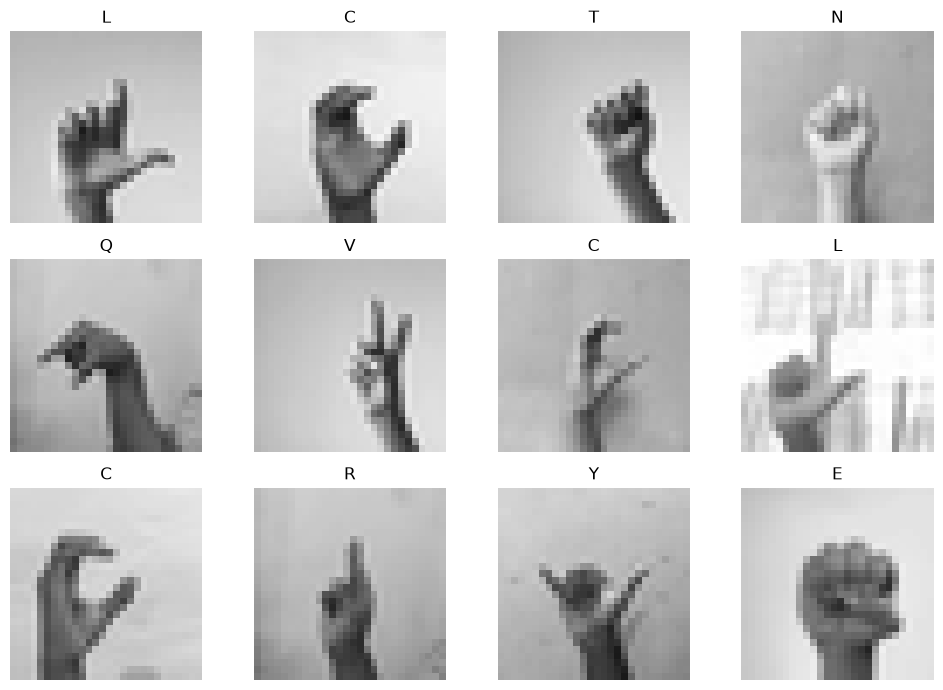

In [25]:
import matplotlib.pyplot as plt

# Display a random selection of hand gesture images with their corresponding labels.
count = min(12, len(X_images))
# Select random indices for displaying images.
indices = np.random.default_rng(42).choice(
    len(X_images), size=count, replace=False
)

# Create a 3x4 grid for displaying the images.
fig, axes = plt.subplots(3, 4, figsize=(10, 7))

# Turn off axes for all subplots initially.
for ax in axes.flat:
    ax.axis("off")

# Display the selected images with their corresponding labels.
letters = "ABCDEFGHIKLMNOPQRSTUVWXY"
for ax, index in zip(axes.flat, indices):
    ax.imshow(X_images[index, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(letters[int(y_images[index])])
# Adjust layout and display the figure.
plt.tight_layout()
plt.show()

In [26]:
X_train, X_val, y_train, y_val = train_test_split(X_images, y_images, test_size=0.2, random_state=42, stratify=y_images)

In [30]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

mnist_df = pd.read_csv("../data/sign_mnist_train.csv")

# Prepare MNIST pixels directly from the CSV.
X_mnist = (
    mnist_df.drop(columns="label")
    .to_numpy(dtype=np.float32)
    .reshape(-1, 28, 28, 1)
    / 255.0
)

# Match the mapping used by your image-folder loader.
letters = "ABCDEFGHIKLMNOPQRSTUVWXY"

original_to_new = {
    ord(letter) - ord("A"): index
    for index, letter in enumerate(letters)
}

mapped_labels = mnist_df["label"].map(original_to_new)

if mapped_labels.isna().any():
    raise ValueError("Unexpected MNIST labels found.")

y_mnist = mapped_labels.to_numpy(dtype=np.int64)

In [31]:
X_mnist_train, X_mnist_val, y_mnist_train, y_mnist_val = (
    train_test_split(
        X_mnist,
        y_mnist,
        test_size=0.2,
        random_state=42,
        stratify=y_mnist,
    )
)

# X_train and y_train are your existing downloaded-image training split.
X_train_combined = np.concatenate(
    [X_train, X_mnist_train], axis=0
)

y_train_combined = np.concatenate(
    [y_train, y_mnist_train], axis=0
)

In [32]:
model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),
        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.4),

        layers.Dense(24, activation='softmax')
    ])

In [33]:
model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,344 (1.62 MB)

 Trainable params: 423,896 (1.62 MB)

 Non-trainable params: 448 (1.75 KB)

In [35]:
early_stop = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

history = model.fit(
        X_train_combined, y_train_combined,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=64,
        callbacks=[early_stop],
        shuffle=True,
        verbose=1
    )

Epoch 1/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 73s 106ms/step - accuracy: 0.8959 - loss: 0.4613 - val_accuracy: 0.9919 - val_loss: 0.1020
Epoch 2/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 71s 110ms/step - accuracy: 0.9986 - loss: 0.0242 - val_accuracy: 0.8379 - val_loss: 0.4628
Epoch 3/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 54s 84ms/step - accuracy: 0.9967 - loss: 0.0231 - val_accuracy: 0.9998 - val_loss: 0.0061
Epoch 4/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 69s 107ms/step - accuracy: 0.9976 - loss: 0.0145 - val_accuracy: 0.9229 - val_loss: 0.2746
Epoch 5/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 57s 89ms/step - accuracy: 0.9980 - loss: 0.0115 - val_accuracy: 0.9100 - val_loss: 0.2783
Epoch 6/15
644/644 ━━━━━━━━━━━━━━━━━━━━ 71s 110ms/step - accuracy: 0.9944 - loss: 0.0217 - val_accuracy: 0.9962 - val_loss: 0.0160
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


In [ ]:
# Plot training & validation accuracy values
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()
plt.tight_layout()
plt.show()

In [36]:
model.evaluate(X_val, y_val)
model.evaluate(X_mnist_val, y_mnist_val)

150/150 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.9998 - loss: 0.0061
172/172 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 1.0000 - loss: 0.0032


[0.0031988373957574368, 1.0]

In [39]:
test_df = pd.read_csv("../data/sign_mnist_test.csv")

print("Dataset shape: ", test_df.shape)
# display(test_df.head())

letters = "ABCDEFGHIKLMNOPQRSTUVWXY"

mapping = {
    ord(letter) - ord("A"): index
    for index, letter in enumerate(letters)
}

mapped_labels = test_df["label"].map(mapping)

if mapped_labels.isna().any():
    raise ValueError("Unexpected test labels found.")

y_test = mapped_labels.to_numpy(dtype=np.int64)

X_test = test_df.drop(columns=['label']).values
X_test = X_test.reshape(-1, 28, 28, 1)
X_test = X_test.astype('float32') / 255.0

Dataset shape:  (7172, 785)


In [41]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size=64, verbose=1)
print("Test loss:", test_loss)
print("Test accuracy:" , test_accuracy)

113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 77ms/step - accuracy: 0.9052 - loss: 0.3593
Test loss: 0.35931918025016785
Test accuracy: 0.9051868319511414


In [43]:
y_scores= model.predict(X_test, verbose=1)
y_pred = np.argmax(y_scores, axis=1)

labels = np.sort(np.unique(y_test))
label_names = [chr(int(label) + ord('A')) for label in labels]

225/225 ━━━━━━━━━━━━━━━━━━━━ 32s 115ms/step


In [47]:
#print(classification_report(y_test, y_pred, labels=labels, target_names=label_names, digits=3, zero_division=0))

              precision    recall  f1-score   support

           A      0.938     1.000     0.968       331
           B      0.983     0.961     0.972       432
           C      0.939     0.945     0.942       310
           D      0.664     1.000     0.798       245
           E      0.982     0.998     0.990       498
           F      0.826     1.000     0.905       247
           G      0.962     0.940     0.951       348
           H      0.911     0.986     0.947       436
           I      0.937     0.872     0.903       288
           K      0.773     0.937     0.847       331
           L      1.000     1.000     1.000       209
           M      0.936     0.815     0.871       394
           N      0.908     0.577     0.706       291
           O      0.989     0.760     0.860       246
           P      0.991     1.000     0.996       347
           Q      0.886     1.000     0.940       164
           R      0.799     0.854     0.826       144
           S      0.888    

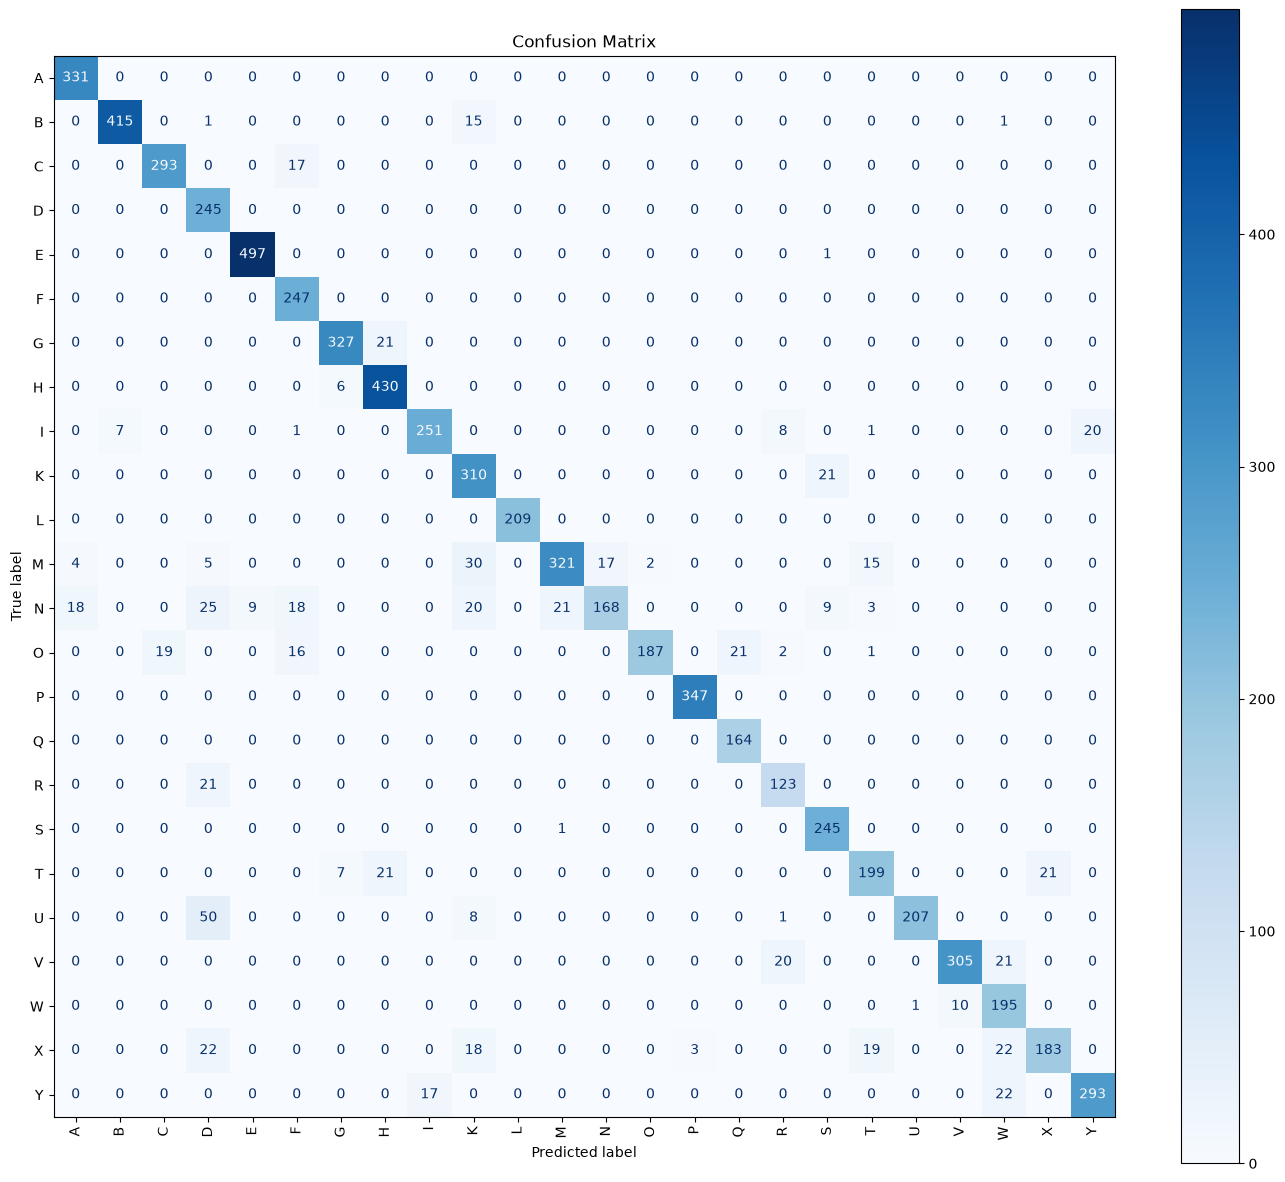

In [48]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
)

letters = "ABCDEFGHIKLMNOPQRSTUVWXY"
labels = np.arange(24)

print(classification_report(
    y_test,
    y_pred,
    labels=labels,
    target_names=list(letters),
    digits=3,
    zero_division=0,
))

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=list(letters),
    cmap="Blues",
    values_format="d",
    ax=ax,
)

ax.set_title("Confusion Matrix")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()